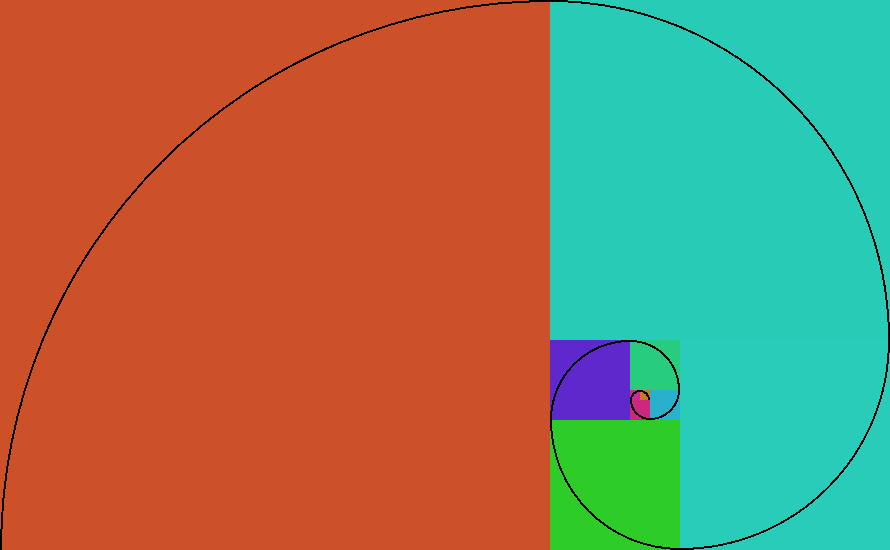

In [25]:
import random
from pytamaro import (
    above,
    beside,
    empty_graphic,
    hsv_color,
    rectangle,
    show_graphic,
    circular_sector,
    Graphic,
    black,
    rotate,
    pin,
    compose,
    bottom_left,
    graphic_width,
    graphic_height,
    Color)


# ORIENTATION:
# 0 = bottom right
# 1 = top right
# 2 = top left
# 3 = bottom left
MIN_SIZE = 10
THICKNESS = 2


def random_color() -> Color:
    return hsv_color(random.randint(0, 360), 0.8, 0.8)

def pin_all_on_bottom_left(graphics: list[Graphic]) -> Graphic:
    result = empty_graphic()
    for graphic in graphics:
        result = compose(pin(bottom_left, graphic), result)
    return result

def tile(size: float) -> Graphic:
    tile_color = random_color()
    rec = rectangle(size, size, tile_color)
    outer_circle = circular_sector(size, 90, black)
    inner_circle = circular_sector(size - THICKNESS, 90, tile_color)
    return pin_all_on_bottom_left([rec, outer_circle, inner_circle])

def orient(orientation: int, graphic: Graphic) -> Graphic:
    return rotate(orientation * 90, graphic)

def fib(n: int) -> Graphic:
    if n < 1:  # base case
        return tile(MIN_SIZE)
    else:
        prev_piece = fib(n - 1)
        size = graphic_height(prev_piece) if n % 2 != 0 else graphic_width(prev_piece)
        new_piece = orient(n % 4, tile(size))
        if n % 4 == 0:
            return above(new_piece, prev_piece)
        elif n % 4 == 1:
            return beside(new_piece, prev_piece)
        elif n % 4 == 2:
            return above(prev_piece, new_piece)
        else:
            return beside(prev_piece, new_piece)


# code that shows result
show_graphic(fib(9))
